# Tópico 6 - Frequência Normalizada

## Visão Geral e Objetivos
Neste notebook, investigamos o conceito de **Frequência Normalizada** em sistemas de tempo discreto [1]. Os principais objetivos são:
1. **Conversão entre Domínios de Frequência**: Compreender e implementar as conversões matemáticas entre frequência física $f$ (Hz), frequência normalizada $f_n$ (ciclos por amostra) e frequência angular discreta $\omega$ (radianos por amostra) [1].
2. **Análise de Invariância Discreta**: Avaliar como variações na frequência de amostragem $f_s$ alteram a representação discreta $\omega = 2\pi \frac{f}{f_s}$ para uma mesma frequência física $f$ [1].
3. **Mapeamento do Intervalo Fundamental**: Demonstrar o limite da banda passante discreta fundamental $-\pi \le \omega \le \pi$ (ou $0 \le f_n \le 0.5$ em magnitude) [1].
4. **Gerenciamento de Imagens**: Exportar os gráficos comparativos diretamente para o diretório local de simulação [2].

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Tabela de Conversão entre Unidades de Frequência

As relações de conversão entre as representações de frequência são dadas por [1]:
- **Frequência Física ($f$)**: expressa em Hertz ($\text{Hz} = \text{ciclos/segundo}$).
- **Frequência Normalizada ($f_n$)**: expressa em ciclos por amostra, dada por $f_n = \frac{f}{f_s}$.
- **Frequência Angular Discreta ($\omega$)**: expressa em radianos por amostra, dada por $\omega = 2\pi f_n = 2\pi \frac{f}{f_s}$.

Abaixo, calculamos analiticamente estas conversões para diferentes frequências físicas ($f = 50, 100, 250, 500\text{ Hz}$) sob duas frequências de amostragem distinta ($f_s = 1000\text{ Hz}$ e $f_s = 8000\text{ Hz}$) [1].

In [2]:
# Tabela comparativa de conversão de frequências
frequencias_f = [50.0, 100.0, 250.0, 500.0]  # em Hz
taxas_fs = [1000.0, 8000.0]                   # em Hz

print(f"{'f (Hz)':<10} | {'fs (Hz)':<10} | {'fn (ciclos/amostra)':<22} | {'w (rad/amostra)':<20}")
print("-" * 70)

for fs in taxas_fs:
    for f in frequencias_f:
        fn = f / fs
        w = 2 * np.pi * fn
        print(f"{f:<10.1f} | {fs:<10.1f} | {fn:<22.4f} | {w/np.pi:<6.3f} * pi ({w:<5.3f} rad)")
    print("-" * 70)

f (Hz)     | fs (Hz)    | fn (ciclos/amostra)    | w (rad/amostra)     
----------------------------------------------------------------------
50.0       | 1000.0     | 0.0500                 | 0.100  * pi (0.314 rad)
100.0      | 1000.0     | 0.1000                 | 0.200  * pi (0.628 rad)
250.0      | 1000.0     | 0.2500                 | 0.500  * pi (1.571 rad)
500.0      | 1000.0     | 0.5000                 | 1.000  * pi (3.142 rad)
----------------------------------------------------------------------
50.0       | 8000.0     | 0.0063                 | 0.013  * pi (0.039 rad)
100.0      | 8000.0     | 0.0125                 | 0.025  * pi (0.079 rad)
250.0      | 8000.0     | 0.0312                 | 0.062  * pi (0.196 rad)
500.0      | 8000.0     | 0.0625                 | 0.125  * pi (0.393 rad)
----------------------------------------------------------------------


## 2. Simulação Visual do Efeito da Taxa de Amostragem ($f_s$) no Domínio Discreto

Consideramos um sinal analógico senoidal de frequência fixa $f = 100\text{ Hz}$ [1]:
$$x(t) = \cos(2\pi \cdot 100 \cdot t)$$

Ao amostrarmos este mesmo sinal com três frequências de amostragem diferentes ($f_{s1} = 400\text{ Hz}$, $f_{s2} = 1000\text{ Hz}$ e $f_{s3} = 4000\text{ Hz}$), a frequência angular discreta observada $\omega_0$ assume valores completamente distintos [1]:
- **Para $f_{s1} = 400\text{ Hz}$**: $\omega_1 = 2\pi \frac{100}{400} = 0.5\pi\text{ rad/amostra}$ ($4$ amostras por ciclo).
- **Para $f_{s2} = 1000\text{ Hz}$**: $\omega_2 = 2\pi \frac{100}{1000} = 0.2\pi\text{ rad/amostra}$ ($10$ amostras por ciclo).
- **Para $f_{s3} = 4000\text{ Hz}$**: $\omega_3 = 2\pi \frac{100}{4000} = 0.05\pi\text{ rad/amostra}$ ($40$ amostras por ciclo).

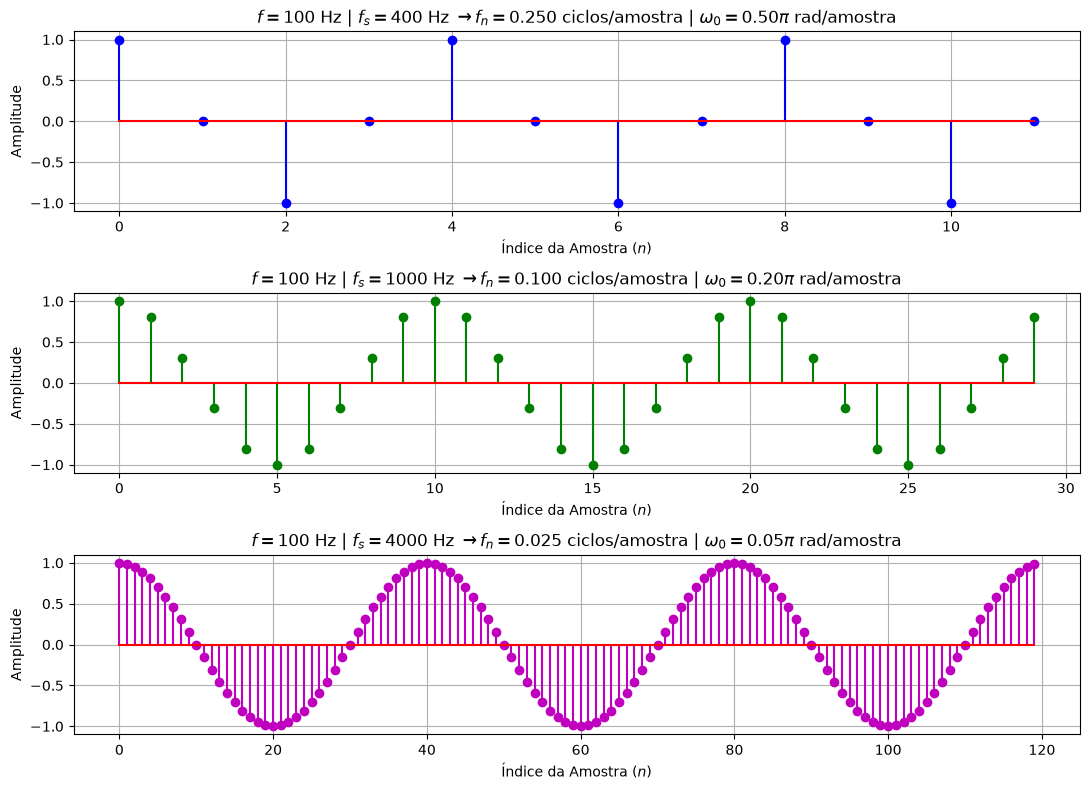

In [3]:
# Sinal analógico original: f = 100 Hz
f_sinal = 100.0

# Três frequências de amostragem distintas
fs_list = [400.0, 1000.0, 4000.0]
cores = ['b', 'g', 'm']

fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=False)

for idx, fs in enumerate(fs_list):
    # Número de amostras correspondente a um tempo fixo de 30 ms
    N_amostras = int(0.03 * fs)
    n = np.arange(N_amostras)
    
    # Frequência normalizada e angular discreta
    fn = f_sinal / fs
    w0 = 2 * np.pi * fn
    
    # Sinal discreto x[n]
    x_n = np.cos(w0 * n)
    
    # Plotagem em número de amostras n
    axs[idx].stem(n, x_n, linefmt=f'{cores[idx]}-', markerfmt=f'{cores[idx]}o', basefmt='r-')
    axs[idx].set_title(f'$f = {f_sinal:.0f}\\text{{ Hz}}$ | $f_s = {fs:.0f}\\text{{ Hz}}$ '
                      f'$\\rightarrow f_n = {fn:.3f}\\text{{ ciclos/amostra}}$ | '
                      f'$\\omega_0 = {w0/np.pi:.2f}\\pi\\text{{ rad/amostra}}$')
    axs[idx].set_xlabel('Índice da Amostra ($n$)')
    axs[idx].set_ylabel('Amplitude')
    axs[idx].grid(True)

plt.tight_layout()

# Salvamento do gráfico no diretório local
fig.savefig("grafico_frequencia_normalizada.png")
plt.show()

## 3. Síntese dos Resultados sobre Frequência Normalizada
- **Dependência de $f_s$**: A frequência discreta $\omega$ não depende unicamente da frequência física do sinal $f$, mas sim da razão $\frac{f}{f_s}$ [1].
- **Amostras por Ciclo**: O inverso da frequência normalizada $\frac{1}{f_n} = \frac{f_s}{f}$ indica a quantidade exata de amostras discretas contidas em um período completo da senoide [1].
- **Faixa Fundamental**: Na análise discreta de Fourier, frequências físicas $f = f_s / 2$ (limite de Nyquist) correspondem à frequência angular máxima $\omega = \pi\text{ rad/amostra}$ (ou $f_n = 0.5\text{ ciclos/amostra}$) [1].